<a href="https://colab.research.google.com/github/LeonardoSaavedra-07/Artificial-Intelligence/blob/main/Practica_8_Filtros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 8. Aplicación de filtros
**Procesamiento Digital de Imágenes — UANL FIME**

**Brígada:** 309 , **Carrera:** IB

**Integrantes:**

Leonardo Saavedra de León - 2093442

Alejandra Janeth Hernández Grimaldo - 1929944

Erick Alejandro Cantú Plascencia - 2105789

Manuel Alejandro Juárez Grimaldo - 2115290

**Objetivo:** aplicar y modificar filtros convolucionales (dominio espacial) y filtros en el dominio de la frecuencia sobre imágenes médicas, explorando parámetros y máscaras para observar sus efectos sobre la calidad y la interpretación visual.

- **Parte I:** filtros con máscaras espaciales sobre una radiografía.
- **Parte II:** filtros en el dominio de la frecuencia (Transformada de Fourier) sobre dos imágenes médicas.

## 0. Librerías y carga de imágenes
Se cargan las librerías y las imágenes. En Colab, si los archivos no existen en el entorno, se abre el cuadro para subirlos. Las imágenes se leen directamente en **escala de grises**.

- Parte I: una radiografía (`RUTA_RX`).
- Parte II: dos imágenes médicas distintas, por ejemplo colonoscopía, endoscopía o cortes histológicos (`RUTAS_P2`).

Sube la radiografía (Parte I)


Saving radiografia.jpeg to radiografia (1).jpeg
Radiografía: radiografia (1).jpeg (630, 462) uint8


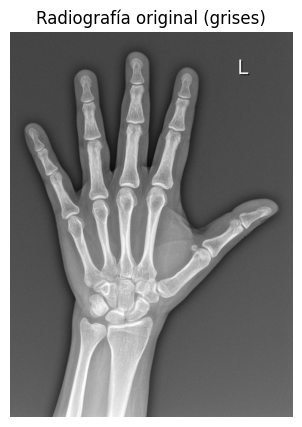

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

RUTA_RX = "radiografia.jpg"                     # cambiar por el nombre de tu radiografía
RUTAS_P2 = ["imagen_a.jpg", "imagen_b.jpg"]     # cambiar por las dos imágenes de la Parte II

def asegurar_archivos(rutas, mensaje):
    faltan = [r for r in rutas if not os.path.exists(r)]
    if not faltan:
        return rutas
    try:
        from google.colab import files
        print(mensaje)
        subidos = list(files.upload().keys())
        return subidos[:len(rutas)]
    except ImportError:
        raise FileNotFoundError(f"No se encontraron los archivos: {faltan}")

RUTA_RX = asegurar_archivos([RUTA_RX], "Sube la radiografía (Parte I)")[0]
img = cv2.imread(RUTA_RX, cv2.IMREAD_GRAYSCALE)
print("Radiografía:", RUTA_RX, img.shape, img.dtype)

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray"); plt.title("Radiografía original (grises)"); plt.axis("off"); plt.show()

# Parte I. Filtros con máscaras espaciales

## 1. Filtros de suavizado
Se aplican tres filtros pasa bajas con kernels de 3×3, 5×5 y 11×11:

- **Media** (`cv2.blur`): promedia los vecinos; reduce ruido pero difumina bordes.
- **Gaussiano** (`cv2.GaussianBlur`): promedio ponderado, da más peso al centro; suaviza con menos pérdida de bordes que la media.
- **Mediana** (`cv2.medianBlur`): toma la mediana de la vecindad; es muy eficaz contra ruido impulsivo (sal y pimienta) y conserva bordes.

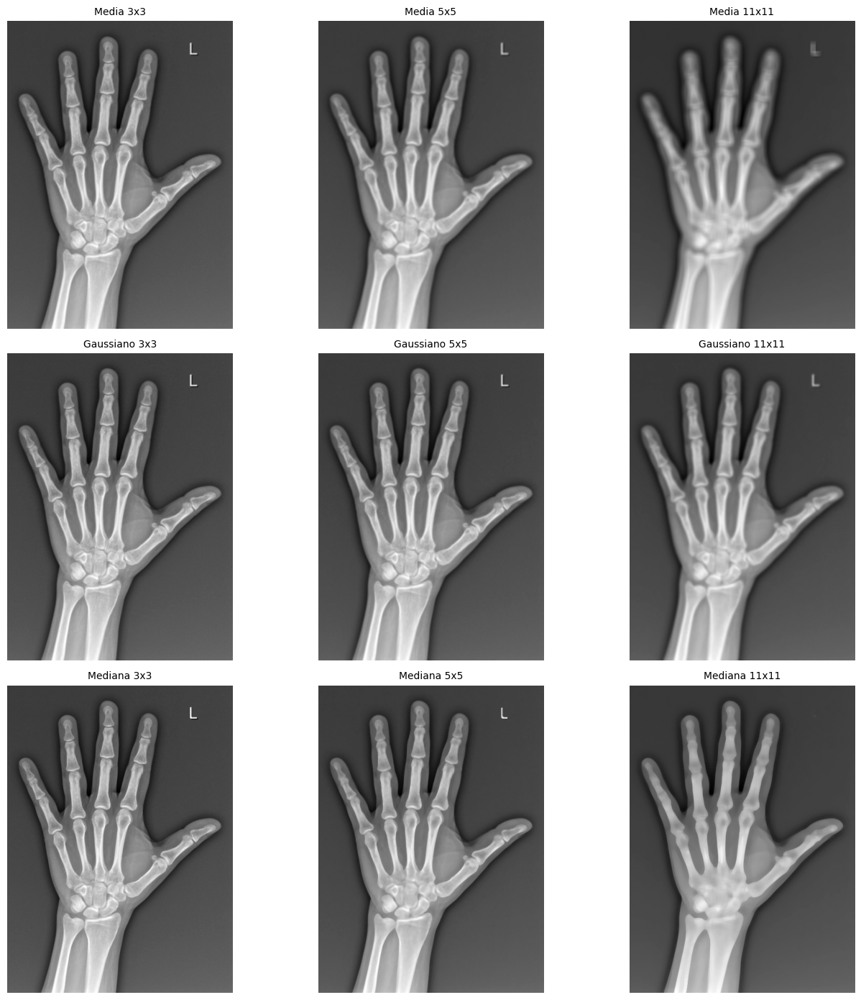

In [ ]:
KERNELS = [3, 5, 11]

def mostrar_grid(imagenes, titulos, filas, columnas, figsize=(14, 10), cmap="gray"):
    fig, ax = plt.subplots(filas, columnas, figsize=figsize)
    ax = np.atleast_2d(ax)
    for a, im, t in zip(ax.ravel(), imagenes, titulos):
        a.imshow(im, cmap=cmap); a.set_title(t, fontsize=10); a.axis("off")
    for a in ax.ravel()[len(imagenes):]:
        a.axis("off")
    plt.tight_layout(); plt.show()

media = {k: cv2.blur(img, (k, k)) for k in KERNELS}
gauss = {k: cv2.GaussianBlur(img, (k, k), 0) for k in KERNELS}
mediana = {k: cv2.medianBlur(img, k) for k in KERNELS}

imagenes, titulos = [], []
for nombre, d in (("Media", media), ("Gaussiano", gauss), ("Mediana", mediana)):
    for k in KERNELS:
        imagenes.append(d[k]); titulos.append(f"{nombre} {k}x{k}")
mostrar_grid(imagenes, titulos, 3, 3, figsize=(14, 14))

### 1.1 Comparación con ruido y justificación del tamaño de kernel
Para decidir el tamaño de kernel se agrega ruido artificial a la radiografía (sal y pimienta, y ruido gaussiano) y se mide:

- **PSNR** respecto a la imagen original (mayor = más cercano a la original, es decir, mejor reducción de ruido).
- **Nitidez** de la imagen filtrada, medida como la varianza del Laplaciano de la imagen limpia filtrada (mayor = conserva más detalle y bordes).

Un buen kernel reduce el ruido sin borrar el detalle útil de la imagen.

Referencia: PSNR sin filtrar -> sal y pimienta: 18.34 dB | gaussiano: 24.62 dB
Nitidez de la imagen original: 205.8

Filtro       k   PSNR s&p (dB)   PSNR gauss (dB)     Nitidez
Media        3           26.97             31.87        27.1
Media        5           28.59             31.01         8.9
Media       11           26.62             27.19         2.1
Gaussiano    3           26.32             31.85        36.3
Gaussiano    5           28.16             32.48        18.2
Gaussiano   11           28.85             30.40         4.0
Mediana      3           38.00             31.00       106.3
Mediana      5           34.99             31.97        79.3
Mediana     11           30.01             28.93        45.3


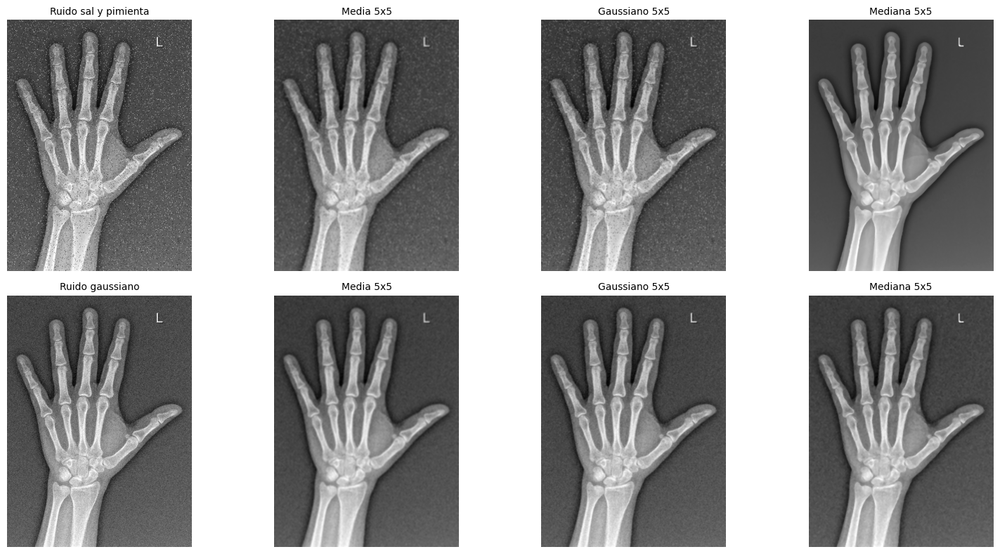

In [ ]:
rng = np.random.default_rng(0)

# Ruido sal y pimienta (5 % de los píxeles)
ruido_sp = img.copy()
m = rng.random(img.shape)
ruido_sp[m < 0.025] = 0
ruido_sp[m > 0.975] = 255

# Ruido gaussiano (sigma = 15)
ruido_g = np.clip(img.astype(np.float32) + rng.normal(0, 15, img.shape), 0, 255).astype(np.uint8)

def nitidez(im):
    return cv2.Laplacian(im, cv2.CV_64F).var()

filtros = {
    "Media":     lambda im, k: cv2.blur(im, (k, k)),
    "Gaussiano": lambda im, k: cv2.GaussianBlur(im, (k, k), 0),
    "Mediana":   lambda im, k: cv2.medianBlur(im, k),
}

print(f"Referencia: PSNR sin filtrar -> sal y pimienta: {cv2.PSNR(img, ruido_sp):.2f} dB | gaussiano: {cv2.PSNR(img, ruido_g):.2f} dB")
print(f"Nitidez de la imagen original: {nitidez(img):.1f}\n")
print(f"{'Filtro':<10}{'k':>4}{'PSNR s&p (dB)':>16}{'PSNR gauss (dB)':>18}{'Nitidez':>12}")
for nombre, f in filtros.items():
    for k in KERNELS:
        p_sp = cv2.PSNR(img, f(ruido_sp, k))
        p_g = cv2.PSNR(img, f(ruido_g, k))
        n = nitidez(f(img, k))
        print(f"{nombre:<10}{k:>4}{p_sp:>16.2f}{p_g:>18.2f}{n:>12.1f}")

mostrar_grid([ruido_sp, filtros["Media"](ruido_sp, 5), filtros["Gaussiano"](ruido_sp, 5), filtros["Mediana"](ruido_sp, 5),
              ruido_g, filtros["Media"](ruido_g, 5), filtros["Gaussiano"](ruido_g, 5), filtros["Mediana"](ruido_g, 5)],
             ["Ruido sal y pimienta", "Media 5x5", "Gaussiano 5x5", "Mediana 5x5",
              "Ruido gaussiano", "Media 5x5", "Gaussiano 5x5", "Mediana 5x5"], 2, 4, figsize=(16, 8))

**Justificación del tamaño de kernel**:
- 3×3: suaviza poco, conserva casi todo el detalle (nitidez más alta), pero reduce poco el ruido.
- 5×5: compromiso entre reducción de ruido y conservación de bordes.
- 11×11: elimina mucho ruido pero difumina estructuras finas; en una radiografía puede borrar detalles de interés (trabéculas, bordes óseos finos).
- Para ruido impulsivo, la mediana supera a la media y al gaussiano; para ruido gaussiano, el filtro gaussiano suele dar el mejor equilibrio.

## 2. Filtros de detección de bordes
Se aplican Sobel en x y en y, Laplaciano y Kirsch, y después se **modifican las máscaras manualmente** para observar las diferencias.

Primero se suaviza ligeramente la imagen (gaussiano 5×5) para que los detectores no amplifiquen el ruido.

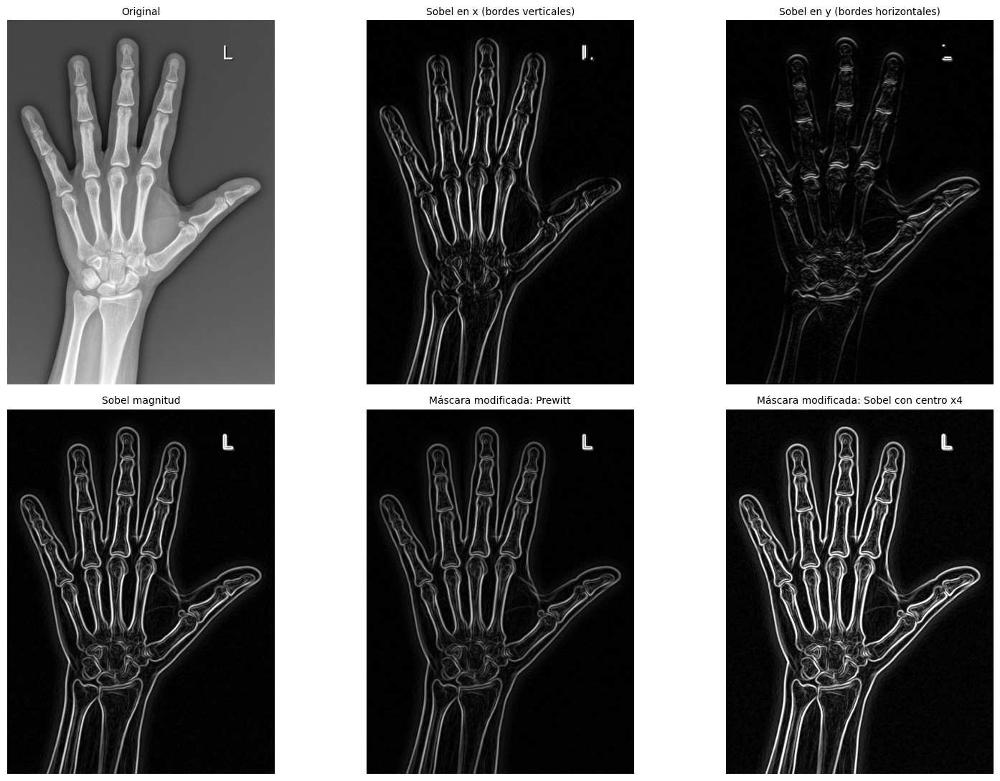

In [ ]:
base = cv2.GaussianBlur(img, (5, 5), 0).astype(np.float32)

def conv(im, kernel):
    return cv2.filter2D(im, cv2.CV_32F, np.array(kernel, dtype=np.float32))

def a_u8(im):
    return cv2.convertScaleAbs(im)

def magnitud(gx, gy):
    return a_u8(np.sqrt(gx**2 + gy**2))

# --- Sobel estándar ---
sobel_x = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
sobel_y = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
gx, gy = conv(base, sobel_x), conv(base, sobel_y)

# --- Sobel con máscaras modificadas ---
prewitt_x = [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]            # pesos iguales (Prewitt)
prewitt_y = [[-1, -1, -1], [0, 0, 0], [1, 1, 1]]
sobel_fuerte_x = [[-1, 0, 1], [-4, 0, 4], [-1, 0, 1]]       # más peso a la fila central
sobel_fuerte_y = [[-1, -4, -1], [0, 0, 0], [1, 4, 1]]

mostrar_grid(
    [img, a_u8(gx), a_u8(gy), magnitud(gx, gy),
     magnitud(conv(base, prewitt_x), conv(base, prewitt_y)),
     magnitud(conv(base, sobel_fuerte_x), conv(base, sobel_fuerte_y))],
    ["Original", "Sobel en x (bordes verticales)", "Sobel en y (bordes horizontales)", "Sobel magnitud",
     "Máscara modificada: Prewitt", "Máscara modificada: Sobel con centro x4"],
    2, 3, figsize=(16, 11))

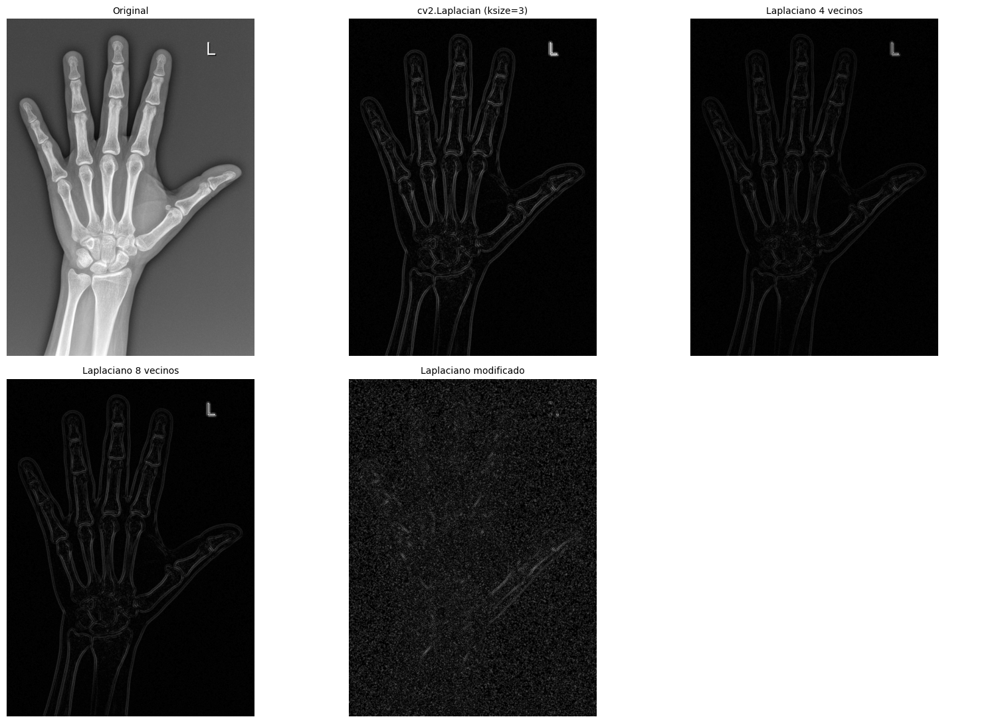

In [ ]:
# --- Laplaciano: estándar (4 vecinos), con 8 vecinos y modificado ---
lap4 = [[0, 1, 0], [1, -4, 1], [0, 1, 0]]
lap8 = [[1, 1, 1], [1, -8, 1], [1, 1, 1]]
lap_mod = [[-1, 2, -1], [2, -4, 2], [-1, 2, -1]]    # modificación manual (suma 0)
lap_cv = cv2.Laplacian(base, cv2.CV_32F, ksize=3)

mostrar_grid(
    [img, a_u8(lap_cv), a_u8(conv(base, lap4)), a_u8(conv(base, lap8)), a_u8(conv(base, lap_mod))],
    ["Original", "cv2.Laplacian (ksize=3)", "Laplaciano 4 vecinos", "Laplaciano 8 vecinos", "Laplaciano modificado"],
    2, 3, figsize=(16, 11))

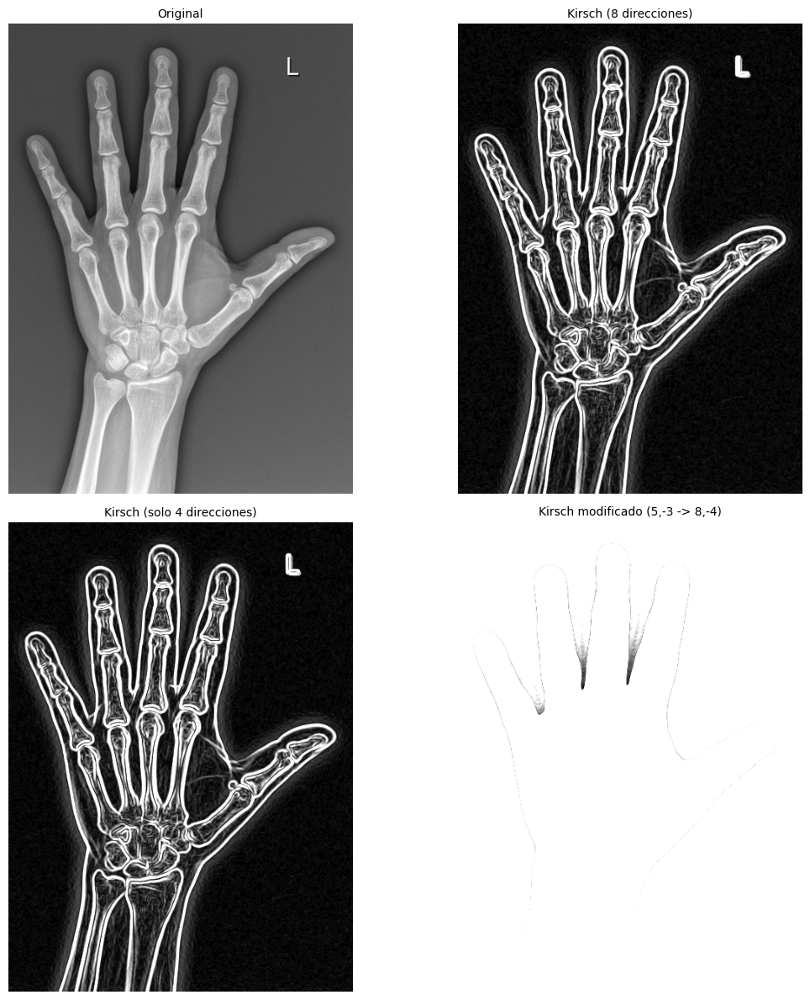

In [ ]:
# --- Kirsch: 8 máscaras de brújula ---
def rotar_kirsch(k):
    k = np.array(k, dtype=np.float32)
    out = k.copy()
    idx = [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1), (2, 0), (1, 0)]
    vals = [k[i] for i in idx]
    vals = vals[-1:] + vals[:-1]
    for i, v in zip(idx, vals):
        out[i] = v
    return out

k0 = [[5, 5, 5], [-3, 0, -3], [-3, -3, -3]]
mascaras_kirsch = [np.array(k0, dtype=np.float32)]
for _ in range(7):
    mascaras_kirsch.append(rotar_kirsch(mascaras_kirsch[-1]))

resp8 = [conv(base, k) for k in mascaras_kirsch]
kirsch8 = a_u8(np.max(np.stack(resp8), axis=0))                       # 8 direcciones
kirsch4 = a_u8(np.max(np.stack([resp8[i] for i in (0, 2, 4, 6)]), axis=0))   # solo 4 direcciones (modificación)

# Kirsch con máscara modificada: ganancia mayor (suma de la máscara sigue siendo 0)
k0_mod = [[8, 8, 8], [-4, 0, -4], [-4, -4, -4]]
m = np.array(k0_mod, dtype=np.float32)
resp_mod = [conv(base, m)]
for _ in range(7):
    m = rotar_kirsch(m); resp_mod.append(conv(base, m))
kirsch_mod = a_u8(np.max(np.stack(resp_mod), axis=0))

mostrar_grid([img, kirsch8, kirsch4, kirsch_mod],
             ["Original", "Kirsch (8 direcciones)", "Kirsch (solo 4 direcciones)", "Kirsch modificado (5,-3 -> 8,-4)"],
             2, 2, figsize=(12, 12))

**Observaciones** *(completar al ver los resultados)*:
- **Sobel:** `Sobel x` resalta bordes verticales y `Sobel y` bordes horizontales; la magnitud combina ambos. Prewitt da pesos iguales (menos énfasis en el píxel central, más sensible al ruido); Sobel con centro ×4 da bordes más marcados.
- **Laplaciano:** es isotrópico (no depende de la dirección) y muy sensible al ruido; la versión de 8 vecinos detecta también bordes diagonales con más intensidad.
- **Kirsch:** al usar 8 direcciones detecta bordes en cualquier orientación; con solo 4 direcciones se pierden los diagonales. Subir la ganancia de la máscara aumenta la respuesta.

## 3. Máscara personalizada (hecha por el alumno)
Se diseñan dos máscaras propias:

1. **Realce (sharpening) suave:** la suma de la máscara es 1, por lo que conserva el brillo medio de la imagen y resalta los detalles. Los vecinos en cruz pesan −1 y las diagonales −0.5.
2. **Detección de bordes diagonales a 45°:** la suma es 0, por lo que responde solo a cambios de intensidad en esa dirección.

Se pueden modificar los valores de las máscaras y volver a ejecutar para observar el efecto.

Suma máscara de realce: 1.0 (debe ser 1 para conservar el brillo)
Suma máscara diagonal : 0.0 (debe ser 0 para detección)


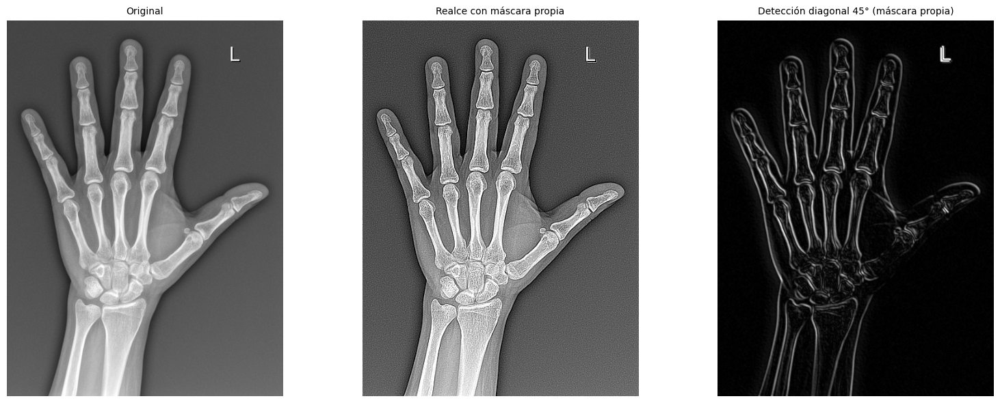

In [ ]:
mascara_realce = np.array([[-0.5, -1, -0.5],
                           [-1,    7, -1],
                           [-0.5, -1, -0.5]], dtype=np.float32)
mascara_diag = np.array([[ 0,  1,  2],
                         [-1,  0,  1],
                         [-2, -1,  0]], dtype=np.float32)

print("Suma máscara de realce:", mascara_realce.sum(), "(debe ser 1 para conservar el brillo)")
print("Suma máscara diagonal :", mascara_diag.sum(), "(debe ser 0 para detección)")

realce = cv2.filter2D(img, -1, mascara_realce)
diag = a_u8(conv(base, mascara_diag))

mostrar_grid([img, realce, diag],
             ["Original", "Realce con máscara propia", "Detección diagonal 45° (máscara propia)"],
             1, 3, figsize=(16, 6))

## 4. Comparación general de la Parte I


- Qué filtro de suavizado funcionó mejor y con qué kernel; por qué.
- Qué detector de bordes marcó mejor las estructuras óseas y cuál fue más sensible al ruido.
- Efecto de las máscaras modificadas frente a las estándar.
- Qué logra la máscara personalizada de realce y la de detección diagonal.

# Parte II. Filtros en el dominio de la frecuencia

## 5. Transformada de Fourier y filtrado
Se lleva cada imagen al dominio de la frecuencia con la FFT 2D, se centra el espectro con `fftshift`, se multiplica por una **máscara** y se regresa al dominio espacial con la transformada inversa.

- **Pasa bajas:** deja pasar frecuencias cercanas al centro (cambios suaves) y elimina las altas: la imagen se difumina.
- **Pasa altas:** elimina frecuencias cercanas al centro y deja las altas (bordes y detalle): la imagen pierde brillo medio y resalta bordes.

Las imágenes se redimensionan a 512×512 para que los radios de corte (20, 50, 80 px) sean comparables entre imágenes.

Sube las dos imágenes de la Parte II


Saving imagen_a.jpeg to imagen_a.jpeg
Saving imagen_b.jpeg to imagen_b.jpeg
imagen_a.jpeg -> (512, 512)
imagen_b.jpeg -> (512, 512)


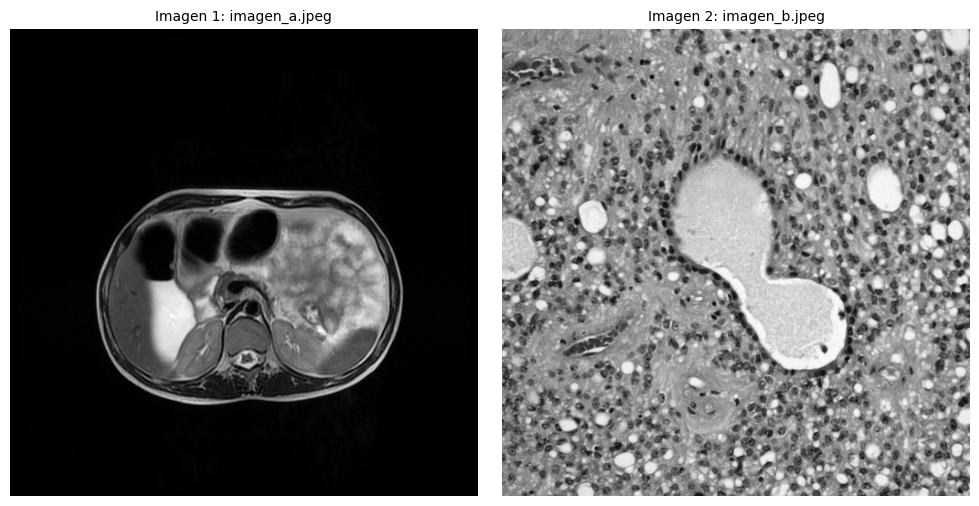

In [ ]:
RUTAS_P2 = asegurar_archivos(RUTAS_P2, "Sube las dos imágenes de la Parte II")
TAM = 512
imgs_p2 = []
for r in RUTAS_P2:
    im = cv2.imread(r, cv2.IMREAD_GRAYSCALE)
    imgs_p2.append(cv2.resize(im, (TAM, TAM)))
    print(r, "->", imgs_p2[-1].shape)

mostrar_grid(imgs_p2, [f"Imagen {i+1}: {r}" for i, r in enumerate(RUTAS_P2)], 1, 2, figsize=(10, 5))

In [ ]:
def distancias(shape):
    filas, cols = shape
    y, x = np.ogrid[:filas, :cols]
    return np.sqrt((y - filas // 2) ** 2 + (x - cols // 2) ** 2)

def espectro(im):
    return np.fft.fftshift(np.fft.fft2(im.astype(np.float32)))

def log_espectro(F):
    return np.log1p(np.abs(F))

def aplicar_mascara(F, mascara):
    Ff = F * mascara
    rec = np.real(np.fft.ifft2(np.fft.ifftshift(Ff)))
    return Ff, rec

def normalizar(im):
    return cv2.normalize(im, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# ---------- Máscaras ----------
def pasa_bajas_ideal(shape, R):
    return (distancias(shape) <= R).astype(np.float32)

def pasa_bajas_gauss(shape, R):
    return np.exp(-(distancias(shape) ** 2) / (2 * R ** 2)).astype(np.float32)

def pasa_altas_circulo(shape, R):
    return (distancias(shape) > R).astype(np.float32)

def pasa_altas_gauss(shape, R):
    return 1 - pasa_bajas_gauss(shape, R)

def anillo(shape, R1, R2):
    d = distancias(shape)
    return ((d >= R1) & (d <= R2)).astype(np.float32)

def pasa_altas_cruz(shape, ancho):
    # Bloquea una cruz (franjas sobre los ejes de frecuencia, incluido el centro) y deja pasar el resto
    filas, cols = shape
    y, x = np.ogrid[:filas, :cols]
    cruz = (np.abs(y - filas // 2) <= ancho) | (np.abs(x - cols // 2) <= ancho)
    return (~cruz).astype(np.float32)

def mostrar_filtro(im, F, mascara, titulo, altas=False):
    Ff, rec = aplicar_mascara(F, mascara)
    rec_vis = normalizar(rec) if altas else np.clip(rec, 0, 255).astype(np.uint8)
    cy, cx = F.shape[0] // 2, F.shape[1] // 2
    pot_orig, pot_filt = np.abs(F) ** 2, np.abs(Ff) ** 2
    pot_orig[cy, cx] = 0; pot_filt[cy, cx] = 0          # se excluye la componente DC (brillo medio)
    energia = 100 * pot_filt.sum() / pot_orig.sum()
    psnr = cv2.PSNR(im, np.clip(rec, 0, 255).astype(np.uint8))
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
    ax[0].imshow(im, cmap="gray"); ax[0].set_title("Original")
    ax[1].imshow(mascara, cmap="gray"); ax[1].set_title(f"Máscara: {titulo}")
    ax[2].imshow(log_espectro(Ff), cmap="gray"); ax[2].set_title("Espectro filtrado (log)")
    ax[3].imshow(rec_vis, cmap="gray"); ax[3].set_title(f"Inversa | energía {energia:.1f} %")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
    return energia, psnr

## 6. Filtros pasa bajas (radios 20, 50 y 80 px)
Se implementan dos pasa bajas: **ideal** (corte abrupto, puede producir anillos o artefactos de *ringing*) y **gaussiano** (transición suave, sin artefactos).


==================== IMAGEN 1: imagen_a.jpeg ====================


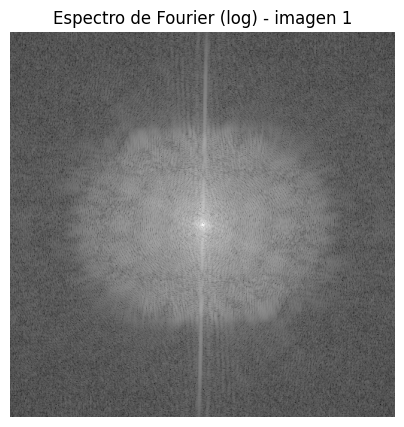

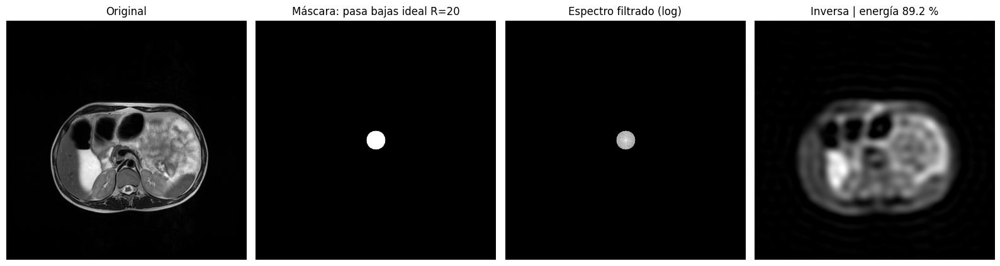

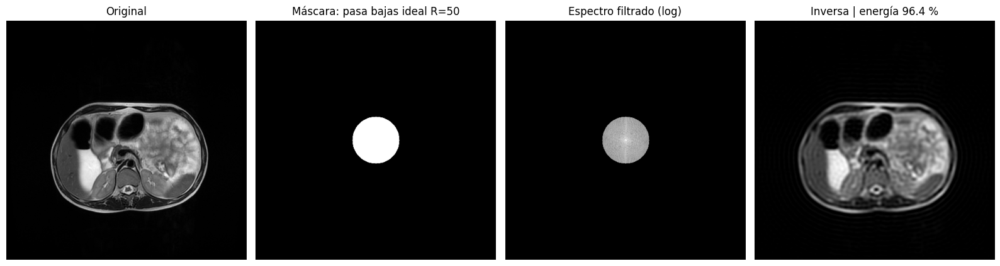

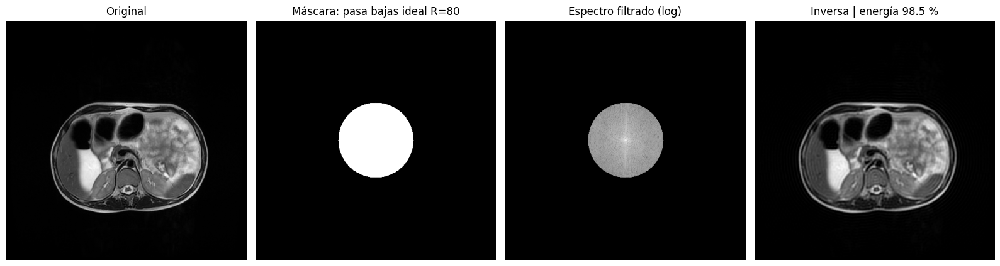

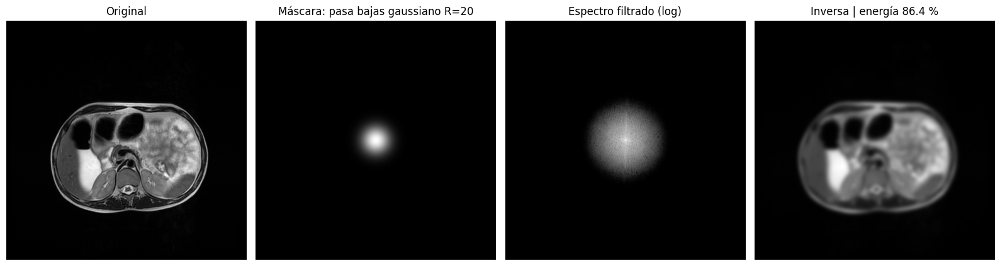

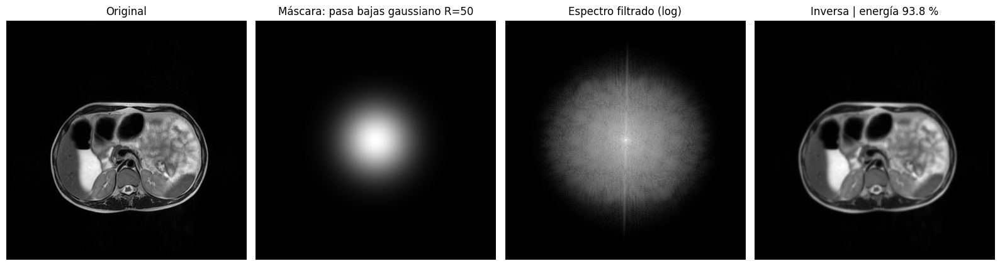

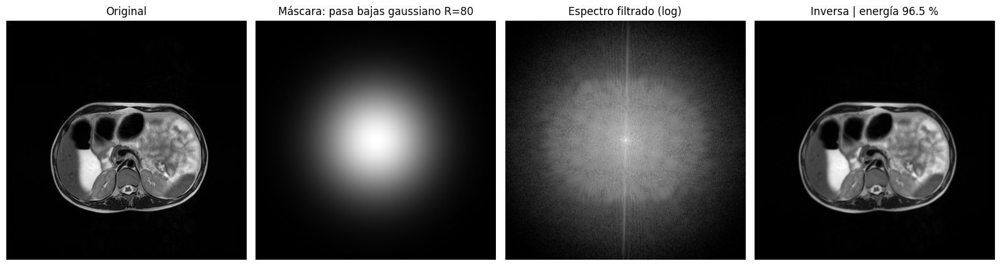


==================== IMAGEN 2: imagen_b.jpeg ====================


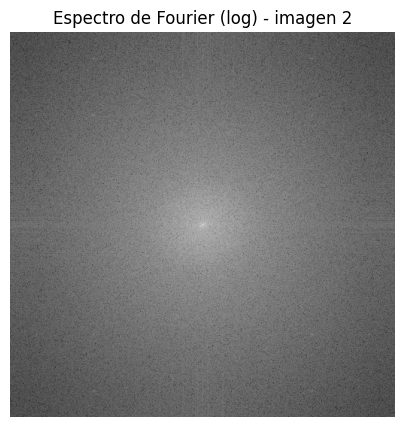

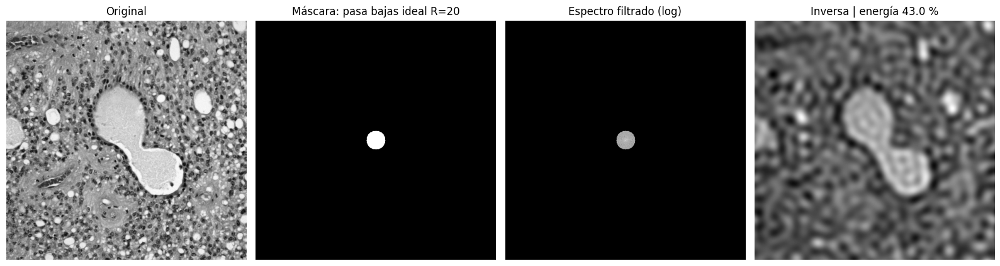

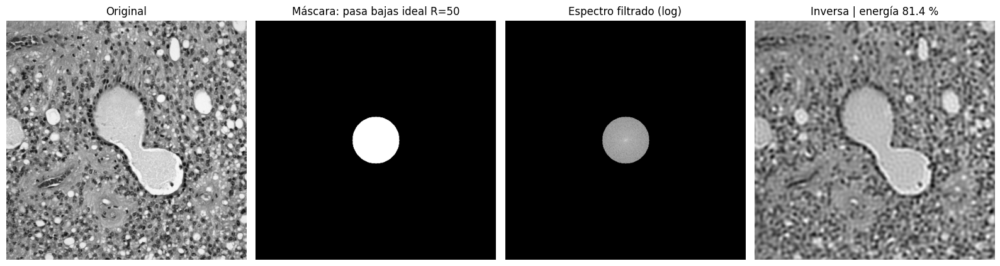

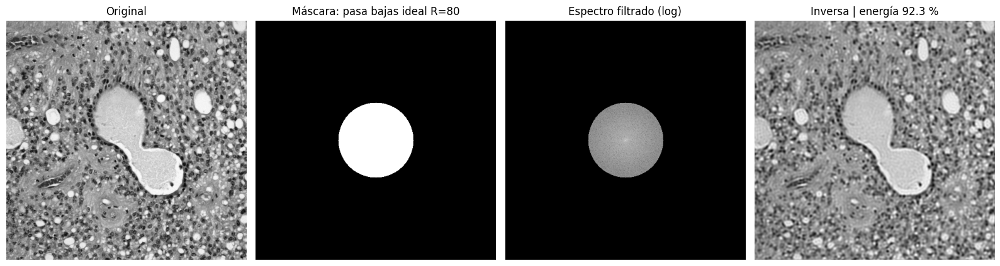

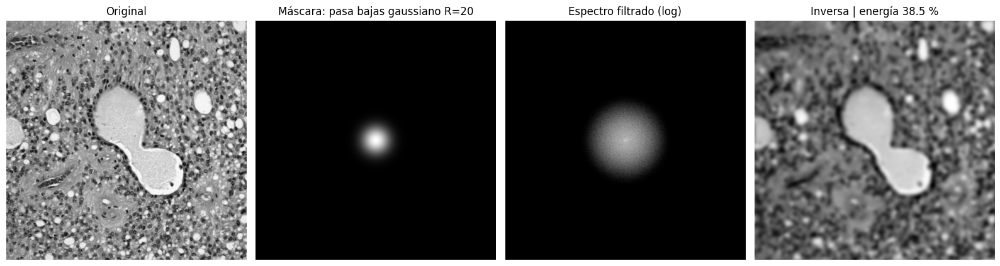

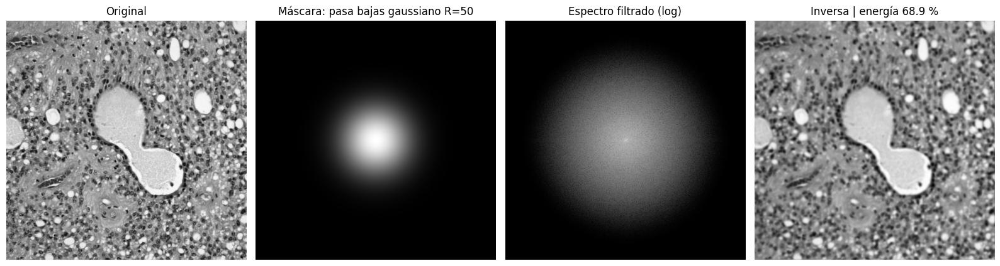

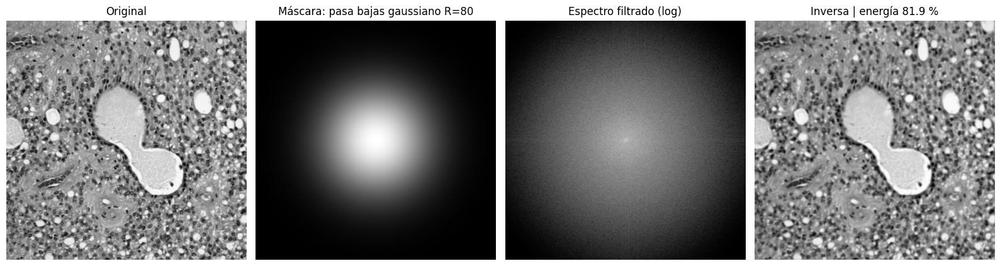

In [ ]:
RADIOS_PB = [20, 50, 80]
resultados = []   # (imagen, filtro, parámetro, energía %, PSNR)

for idx, im in enumerate(imgs_p2, start=1):
    print(f"\n==================== IMAGEN {idx}: {RUTAS_P2[idx-1]} ====================")
    F = espectro(im)
    fig = plt.figure(figsize=(5, 5)); plt.imshow(log_espectro(F), cmap="gray")
    plt.title(f"Espectro de Fourier (log) - imagen {idx}"); plt.axis("off"); plt.show()

    for R in RADIOS_PB:
        e, p = mostrar_filtro(im, F, pasa_bajas_ideal(im.shape, R), f"pasa bajas ideal R={R}")
        resultados.append((idx, "PB ideal", f"R={R}", e, p))
    for R in RADIOS_PB:
        e, p = mostrar_filtro(im, F, pasa_bajas_gauss(im.shape, R), f"pasa bajas gaussiano R={R}")
        resultados.append((idx, "PB gaussiano", f"R={R}", e, p))

## 7. Filtros pasa altas (círculo, gaussiano, anillo y cruz)
Se implementan cuatro configuraciones:

- **Círculo (ideal):** elimina las frecuencias dentro de un círculo de radio R.
- **Gaussiano:** versión suave del anterior.
- **Anillo:** deja pasar solo una banda de frecuencias entre dos radios (banda media).
- **Cruz:** bloquea franjas sobre los ejes de frecuencia (elimina estructuras horizontales y verticales) y deja pasar el resto.

En las imágenes pasa altas se normaliza el resultado para poder visualizarlo (no tiene brillo medio).


==================== IMAGEN 1: imagen_a.jpeg ====================


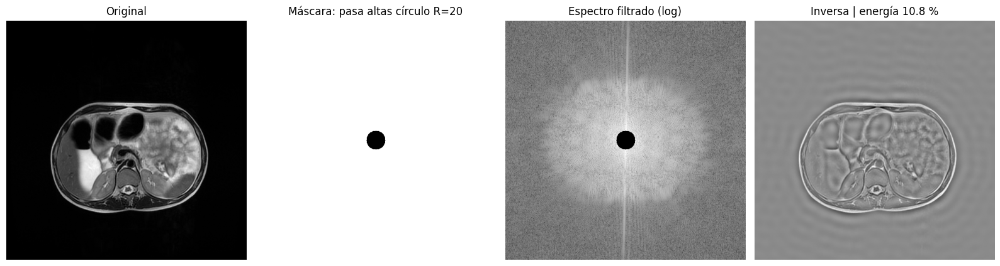

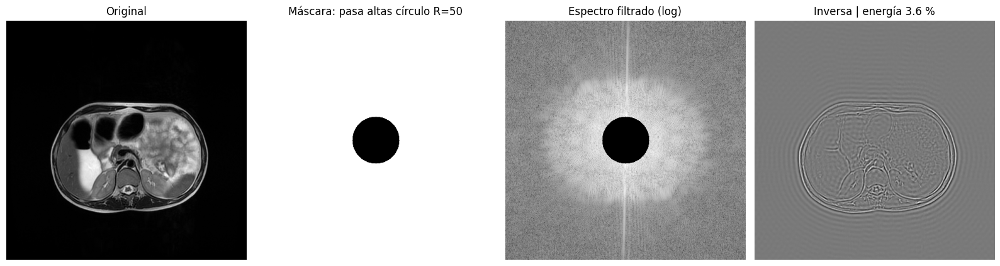

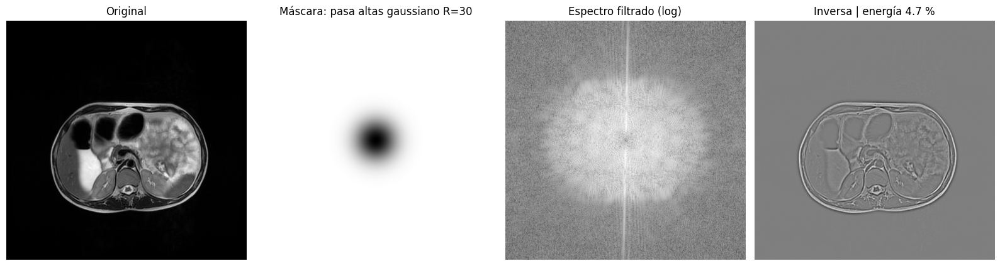

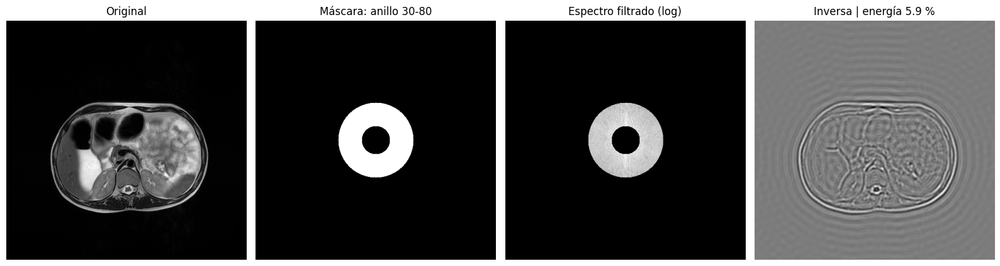

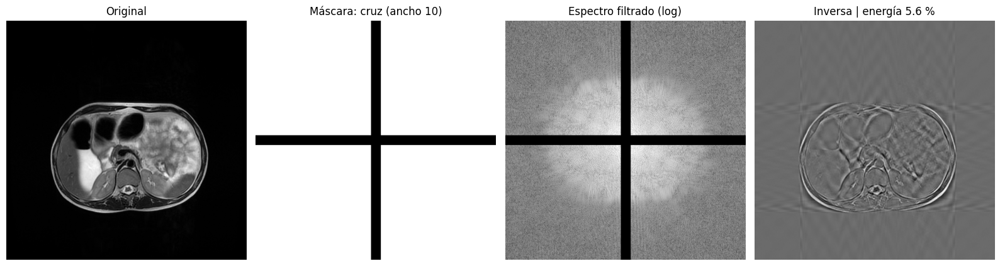


==================== IMAGEN 2: imagen_b.jpeg ====================


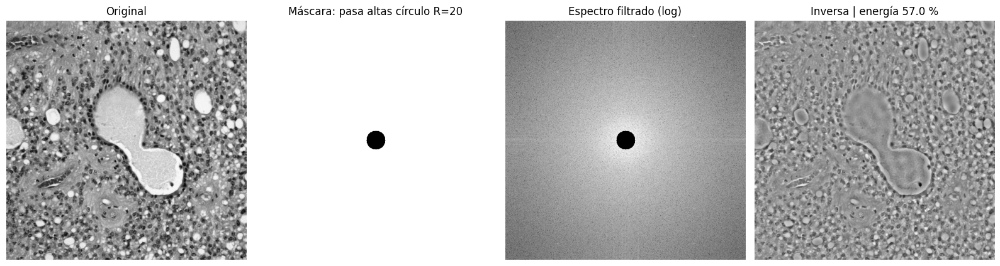

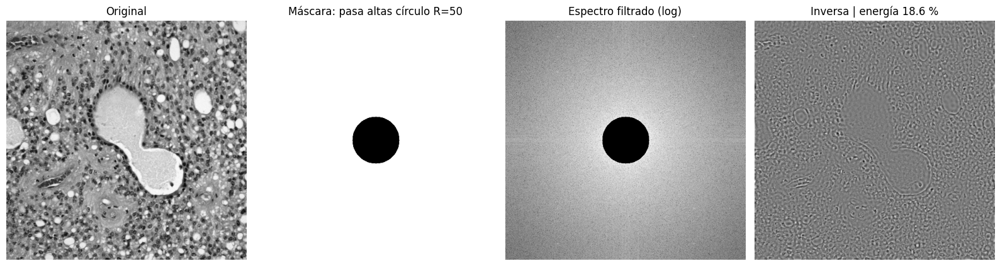

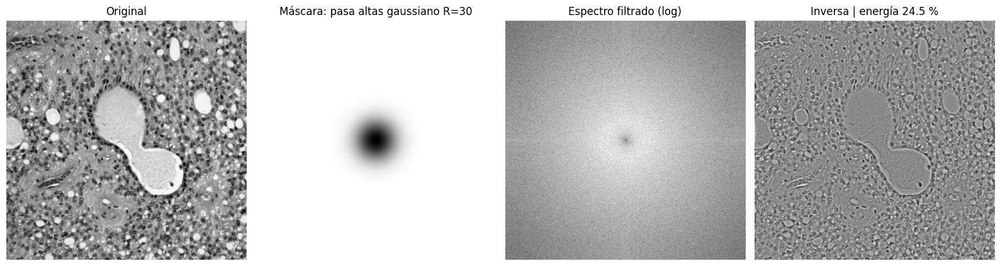

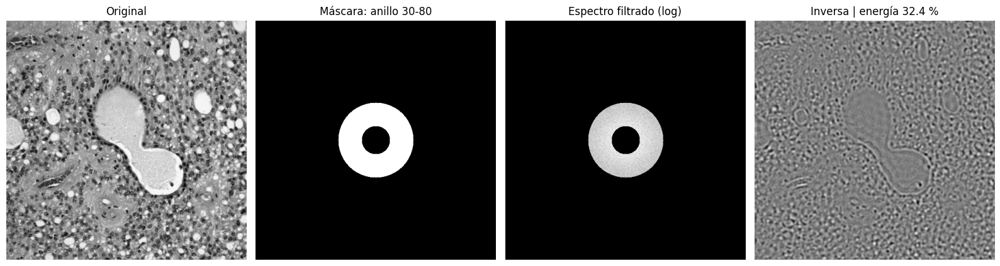

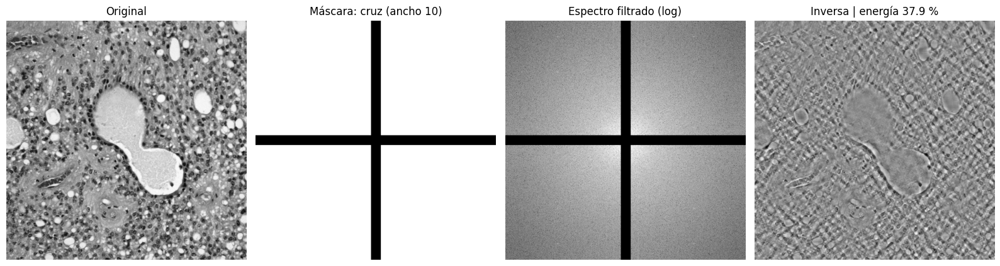

In [ ]:
for idx, im in enumerate(imgs_p2, start=1):
    print(f"\n==================== IMAGEN {idx}: {RUTAS_P2[idx-1]} ====================")
    F = espectro(im)
    for R in (20, 50):
        e, p = mostrar_filtro(im, F, pasa_altas_circulo(im.shape, R), f"pasa altas círculo R={R}", altas=True)
        resultados.append((idx, "PA círculo", f"R={R}", e, p))
    e, p = mostrar_filtro(im, F, pasa_altas_gauss(im.shape, 30), "pasa altas gaussiano R=30", altas=True)
    resultados.append((idx, "PA gaussiano", "R=30", e, p))
    e, p = mostrar_filtro(im, F, anillo(im.shape, 30, 80), "anillo 30-80", altas=True)
    resultados.append((idx, "Anillo", "30-80", e, p))
    e, p = mostrar_filtro(im, F, pasa_altas_cruz(im.shape, 10), "cruz (ancho 10)", altas=True)
    resultados.append((idx, "PA cruz", "ancho=10", e, p))

## 8. Resumen cuantitativo: nitidez y pérdida de información
- **Energía conservada (%):** porcentaje de la energía del espectro (sin contar la componente DC o brillo medio, que domina el total) que pasa por la máscara. Un valor bajo implica que se eliminó mucha información de la imagen.
- **PSNR (dB):** similitud entre la imagen filtrada y la original (solo tiene sentido comparar en pasa bajas; en pasa altas es bajo porque se elimina el brillo medio).

In [ ]:
print(f"{'Img':<5}{'Filtro':<15}{'Parámetro':<12}{'Energía (%)':>14}{'PSNR (dB)':>12}")
for idx, filtro, par, e, p in resultados:
    print(f"{idx:<5}{filtro:<15}{par:<12}{e:>14.2f}{p:>12.2f}")

Img  Filtro         Parámetro      Energía (%)   PSNR (dB)
1    PB ideal       R=20                 89.15       23.66
1    PB ideal       R=50                 96.38       28.47
1    PB ideal       R=80                 98.54       32.43
1    PB gaussiano   R=20                 86.40       25.19
1    PB gaussiano   R=50                 93.78       30.66
1    PB gaussiano   R=80                 96.45       35.16
2    PB ideal       R=20                 42.95       20.55
2    PB ideal       R=50                 81.45       25.43
2    PB ideal       R=80                 92.30       29.23
2    PB gaussiano   R=20                 38.50       22.17
2    PB gaussiano   R=50                 68.94       27.65
2    PB gaussiano   R=80                 81.92       31.66
1    PA círculo     R=20                 10.85       13.98
1    PA círculo     R=50                  3.62       13.40
1    PA gaussiano   R=30                  4.67       13.61
1    Anillo         30-80                 5.94       13.

## 9. Análisis y conclusiones


- **Pasa bajas:** a mayor radio se conserva más detalle (más energía y mayor PSNR); con R=20 la imagen queda muy borrosa. El filtro ideal puede generar *ringing*, el gaussiano no.
- **Pasa altas:** resaltan bordes y texturas, pero pierden la información de brillo global; en el círculo, un radio mayor deja solo los bordes más finos.
- **Anillo:** conserva una banda intermedia; muestra estructuras de tamaño medio.
- **Cruz:** elimina patrones orientados en horizontal y vertical.
- **Comparación entre las dos imágenes:** cómo cambia el efecto según el contenido (más bordes o más textura).
- **Espacial vs. frecuencia:** diferencias de uso y costo entre ambos enfoques.

## Referencias
1. Repositorio de la clase: https://github.com/dilp90/PDI/tree/main/DominioDelEspacio
2. Notebook de referencia, filtros con máscaras: https://github.com/dilp90/PDI/blob/main/DominioDelEspacio/PDI_8_FiltrosConMascaras.ipynb
3. Notebook de referencia, Fourier pasa bajas y pasa altas: https://github.com/dilp90/PDI/blob/main/DominioDeLaFrecuencia/TransformadaFourier_FiltroPasaBajas_y_PasaAlta.ipynb
4. Fuente de las imágenes utilizadas: (agregar enlaces)
5. Referencias consultadas por el equipo: (agregar)